In [12]:
import math
import ast
import pandas as pd
from collections import Counter
from typing import List
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from tqdm import tqdm
from time import time

In [13]:
TRAIN_CSV = "data/train_6x6_mazes.csv"
TEST_CSV  = "data/test_6x6_mazes.csv"
SAVE_PATH = "transformer_model.pth"
VAL_FRAC  = 0.1           # 10% of train → validation

In [14]:
D_MODEL = 128
NHEAD = 8
NUM_LAYERS = 6
DIM_FEEDFORWARD = 512
DROPOUT = 0.1

BATCH_SIZE = 64
EPOCHS = 20
LEARNING_RATE = 1e-4

PAD_TOKEN = "<PAD>"
SOS_TOKEN = "<SOS>"
EOS_TOKEN = "<EOS>"

PAD_IDX = 0
SOS_IDX = 1
EOS_IDX = 2

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(DEVICE)

cuda


In [15]:
class PositionalEncoding(nn.Module):
    def __init__(self, d_model: int, max_len: int = 1000, dropout: float = 0.1, batch_first: bool = False):
        super().__init__()
        self.dropout = nn.Dropout(dropout)
        self.batch_first = batch_first

        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len).unsqueeze(1).float()
        div_term = torch.exp(
            torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model)
        )

        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)

        pe = pe.unsqueeze(1)   # (max_len, 1, d_model)
        self.register_buffer("pe", pe)

    def forward(self, x):
        if self.batch_first:
            seq_len = x.size(1)
            pos = self.pe[:seq_len].transpose(0, 1)
            x = x + pos
        else:
            seq_len = x.size(0)
            x = x + self.pe[:seq_len]
        return self.dropout(x)


###############################################################################
# Transformer Encoder–Decoder
###############################################################################
class TransformerSeq2Seq(nn.Module):
    def __init__(self, vocab_size):
        super().__init__()

        self.embedding = nn.Embedding(vocab_size, D_MODEL, padding_idx=PAD_IDX)
        self.pos_encoder = PositionalEncoding(D_MODEL, dropout=DROPOUT, batch_first=True)
        self.pos_decoder = PositionalEncoding(D_MODEL, dropout=DROPOUT, batch_first=True)

        enc_layer = nn.TransformerEncoderLayer(
            d_model=D_MODEL,
            nhead=NHEAD,
            dim_feedforward=DIM_FEEDFORWARD,
            dropout=DROPOUT,
            batch_first=True
        )
        self.encoder = nn.TransformerEncoder(enc_layer, NUM_LAYERS)

        dec_layer = nn.TransformerDecoderLayer(
            d_model=D_MODEL,
            nhead=NHEAD,
            dim_feedforward=DIM_FEEDFORWARD,
            dropout=DROPOUT,
            batch_first=True
        )
        self.decoder = nn.TransformerDecoder(dec_layer, NUM_LAYERS)

        self.output_layer = nn.Linear(D_MODEL, vocab_size)

        self._init_parameters()

    def _init_parameters(self):
        for p in self.parameters():
            if p.dim() > 1:
                nn.init.xavier_uniform_(p)

    # masking for autoregressive decoding
    @staticmethod
    def generate_square_subsequent_mask(sz, device):
        mask = torch.triu(torch.ones(sz, sz, device=device), diagonal=1).bool()
        return mask

    @staticmethod
    def make_padding_mask(seq):
        return seq == PAD_IDX

    def forward(self, src, tgt): # uses teacher forcing inside decoder returns unnormalized logits
        """
        src: (B,S)
        tgt: (B,T) - tgt[:,0] must be SOS, computing next tokens
        """
        B, S = src.shape
        _, T = tgt.shape

        src_emb = self.embedding(src) * math.sqrt(D_MODEL)
        tgt_emb = self.embedding(tgt) * math.sqrt(D_MODEL)

        src_emb = self.pos_encoder(src_emb)
        tgt_emb = self.pos_decoder(tgt_emb)

        src_pad_mask = self.make_padding_mask(src)
        tgt_pad_mask = self.make_padding_mask(tgt)
        tgt_mask = self.generate_square_subsequent_mask(T, src.device)

        memory = self.encoder(src_emb, src_key_padding_mask=src_pad_mask)

        out = self.decoder(
            tgt_emb,
            memory,
            tgt_mask=tgt_mask,
            tgt_key_padding_mask=tgt_pad_mask,
            memory_key_padding_mask=src_pad_mask
        )

        return self.output_layer(out)

    # Greedy decoding for inference/test
    def greedy_decode(self, src, max_len=200):
        """
        Autoregressive greedy decode that returns:
          - sequences : list[list[int]]  (predicted token ids, trimmed at EOS)
          - logits    : Tensor (B, T_out, V)  raw logits per step (not softmaxed)
          - lengths   : Tensor (B,) lengths (number of predicted tokens per sample, excludes EOS)
        Use these logits + lengths to compute CE loss during validation/test.
        """
        self.eval()
        device = src.device
        src = src.to(device)
        B = src.size(0)

        src_emb = self.embedding(src) * math.sqrt(D_MODEL)
        src_emb = self.pos_encoder(src_emb)
        src_pad_mask = self.make_padding_mask(src)

        memory = self.encoder(src_emb, src_key_padding_mask=src_pad_mask)

        ys = torch.full((B, 1), SOS_IDX, dtype=torch.long, device=device)

        finished = torch.zeros(B, dtype=torch.bool, device=device)
        sequences = [[] for _ in range(B)]
        logits_list = []  # list of (B, V) tensors for each step

        for _ in range(max_len):
            tgt_emb = self.embedding(ys) * math.sqrt(D_MODEL)
            tgt_emb = self.pos_decoder(tgt_emb)

            T = ys.size(1)
            tgt_mask = self.generate_square_subsequent_mask(T, device)
            tgt_pad_mask = self.make_padding_mask(ys)

            out = self.decoder(
                tgt_emb,
                memory,
                tgt_mask=tgt_mask,
                tgt_key_padding_mask=tgt_pad_mask,
                memory_key_padding_mask=src_pad_mask
            )

            step_logits = self.output_layer(out[:, -1, :])  # (B, V)
            logits_list.append(step_logits)

            next_token = step_logits.argmax(dim=-1)  # (B,)

            # append to sequences for unfinished examples
            for idx in range(B):
                if not finished[idx]:
                    sequences[idx].append(next_token[idx].item())

            # mark finished when EOS predicted
            finished |= (next_token == EOS_IDX)

            # append tokens for next iteration
            ys = torch.cat([ys, next_token.unsqueeze(1)], dim=1)

            if finished.all():
                break

        # if no steps produced
        if len(logits_list) == 0:
            V = self.output_layer.weight.size(0)
            return sequences, torch.zeros((B, 0, V), device=device), torch.zeros(B, dtype=torch.long, device=device)

        # Stack logits_list -> (B, T_out, V)
        # each element of logits_list is (B, V); stacking with dim=1 yields (B, T_out, V)
        logits = torch.stack(logits_list, dim=1)

        # lengths: number of predicted tokens per sequence (exclude EOS)
        lengths = torch.tensor([len(s) for s in sequences], dtype=torch.long, device=device)

        # For convenience, trim sequences at EOS if present (already done above by stopping append after EOS)
        # but ensure sequences don't contain EOS token (we appended token ids as output of argmax)
        for i in range(B):
            if EOS_IDX in sequences[i]:
                first = sequences[i].index(EOS_IDX)
                sequences[i] = sequences[i][:first]

        return sequences, logits, lengths


In [ ]:
def parse_sequence(seq_str):
    return ast.literal_eval(seq_str)



def build_vocab(src, tgt):
    counter = Counter()
    for s in src: counter.update(s)
    for t in tgt: counter.update(t)

    tokens = [PAD_TOKEN, SOS_TOKEN, EOS_TOKEN]
    for tok, _ in counter.most_common():
        if tok not in tokens:
            tokens.append(tok)

    tok2id = {tok: i for i, tok in enumerate(tokens)}
    id2tok = {i: tok for tok, i in tok2id.items()}
    return tok2id, id2tok



def convert_to_ids(list_of_seqs, tok2id):
    return [[tok2id.get(tok, PAD_IDX) for tok in seq] for seq in list_of_seqs]



class MazeDataset(Dataset):
    def __init__(self, src, tgt):
        self.src = src
        self.tgt = tgt

    def __len__(self):
        return len(self.src)

    def __getitem__(self, idx):
        return torch.tensor(self.src[idx]), torch.tensor(self.tgt[idx])



def collate(batch):
    src, tgt = zip(*batch)
    src = nn.utils.rnn.pad_sequence(src, batch_first=True, padding_value=PAD_IDX)
    tgt = nn.utils.rnn.pad_sequence(tgt, batch_first=True, padding_value=PAD_IDX)
    return src, tgt



In [17]:
def train_one_epoch(model, loader, optimizer, criterion, epoch=None):
    """
    Train for one epoch with teacher forcing.
    Returns: (avg_loss, seq_accuracy_pct, token_accuracy_pct)
    """
    model.train()
    tot_loss = 0.0
    preds_seq, gold_seq = [] , []

    desc = f"Epoch {epoch}" if epoch is not None else "Training"
    loader_iter = tqdm(loader, desc=desc, unit="batch", leave=False)

    for src, tgt in loader_iter:
        src, tgt = src.to(DEVICE), tgt.to(DEVICE)

        inp = tgt[:, :-1]   # teacher-forcing inputs (include SOS)
        out = tgt[:, 1:]    # targets (no SOS)

        optimizer.zero_grad()
        logits = model(src, inp)  # expected shape: (batch, seq_len, vocab)
        loss = criterion(logits.reshape(-1, logits.size(-1)), out.reshape(-1))
        loss.backward()

        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()

        tot_loss += loss.item()

        # predicted tokens (per-position) from logits
        preds = logits.argmax(dim=-1)          # (batch, seq_len)
        preds_seq.extend(preds.cpu().tolist()) # list of lists
        gold_seq.extend(tgt.cpu().tolist())    # keep full target (includes SOS / PAD / EOS)

        loader_iter.set_postfix(loss=loss.item())

    avg_loss = tot_loss / len(loader)
    seq_acc = seq_accuracy(preds_seq, gold_seq)
    tok_acc = token_accuracy(preds_seq, gold_seq)

    return avg_loss, seq_acc, tok_acc



In [ ]:
def _trim_to_eos(seq_tensor, eos_idx):
    """Return tensor sliced up to (but not including) the first EOS token, if any."""
    eos_positions = (seq_tensor == eos_idx).nonzero(as_tuple=True)[0]
    if eos_positions.numel() > 0:
        return seq_tensor[: eos_positions[0]]
    return seq_tensor


def seq_accuracy(pred_seqs, target_seqs, pad_idx=PAD_IDX, sos_idx=SOS_IDX, eos_idx=EOS_IDX):
    correct = 0
    total = len(pred_seqs)
    print(pred_seqs[0], target_seqs[0])
    for p, t in zip(pred_seqs, target_seqs):
        # convert python lists → tensors if needed
        p = torch.tensor(p) if not torch.is_tensor(p) else p
        t = torch.tensor(t) if not torch.is_tensor(t) else t

        # remove PAD tokens from target
        mask = t != pad_idx
        target_clean = t[mask]

        # remove leading SOS token from target if present (predictions do not include SOS)
        if target_clean.numel() > 0 and target_clean[0].item() == sos_idx:
            target_clean = target_clean[1:]

        target_clean = _trim_to_eos(target_clean, eos_idx)
        p = _trim_to_eos(p, eos_idx)

        # exact sequence match
        if p.numel() != target_clean.numel():
            continue

        if torch.equal(p, target_clean):
            correct += 1

    return 100 * correct / max(1, total)


def token_accuracy(pred_seqs, target_seqs, pad_idx=PAD_IDX, sos_idx=SOS_IDX, eos_idx=EOS_IDX):
    """
    Token-level accuracy:
      correct_tokens / total_target_tokens (excluding PAD and initial SOS).
    Predictions trimmed at EOS; tokens beyond prediction length count as incorrect.
    Returns percentage (0-100).
    """
    correct = 0
    total = 0

    for p, t in zip(pred_seqs, target_seqs):
        p = torch.tensor(p) if not torch.is_tensor(p) else p
        t = torch.tensor(t) if not torch.is_tensor(t) else t

        # clean target: remove PAD tokens
        mask = t != pad_idx
        target_clean = t[mask]

        # remove leading SOS if present
        if target_clean.numel() > 0 and target_clean[0].item() == sos_idx:
            target_clean = target_clean[1:]

        target_clean = _trim_to_eos(target_clean, eos_idx)
        p = _trim_to_eos(p, eos_idx)

        tgt_len = target_clean.numel()
        if tgt_len == 0:
            continue

        total += tgt_len

        # count matches up to min length
        minlen = min(p.numel(), tgt_len)
        if minlen > 0:
            correct += int((p[:minlen] == target_clean[:minlen]).sum().item())

        # tokens in target beyond prediction length are incorrect (we don't add anything for them)

    return 100 * correct / max(1, total)


In [19]:
def evaluate(model, loader, criterion):
    model.eval()
    tot_loss = 0
    preds_seq, gold_seq = [], []  # list of list

    with torch.no_grad():
        loader_iter = tqdm(loader, desc="Evaluating", unit="batch", leave=False)
        for src, tgt in loader_iter:
            src, tgt = src.to(DEVICE), tgt.to(DEVICE)

            inp = tgt[:, :-1]
            out = tgt[:, 1:]



            # gen, logits, _ = model.greedy_decode(src, max_len=out.size(1))
            logits = model(src, inp)
            loss = criterion(logits.reshape(-1, logits.size(-1)), out.reshape(-1))
            tot_loss += loss.item()

            # get gen from greedy decoding
            gen = model.greedy_decode(src, max_len=out.size(1))[0]
            preds_seq.extend(gen)
            gold_seq.extend(tgt.cpu().tolist())

    avg_loss = tot_loss / len(loader)
    seq_acc = seq_accuracy(preds_seq, gold_seq)
    tok_acc = token_accuracy(preds_seq, gold_seq)
    return avg_loss, seq_acc, tok_acc

In [20]:
print("Loading training CSV...")
df = pd.read_csv(TRAIN_CSV)

# read train sequences
src_raw, tgt_raw = [], []
for _, r in df.iterrows():
    s = parse_sequence(r["input_sequence"])
    t = parse_sequence(r["output_path"])

    if t[0] != SOS_TOKEN:
        t = [SOS_TOKEN] + t
    if t[-1] != EOS_TOKEN:
        t = t + [EOS_TOKEN]

    src_raw.append(s)
    tgt_raw.append(t)

# -----------------------
# create validation split
# -----------------------
N = len(src_raw)
split_idx = int(N * (1 - VAL_FRAC))

train_src_raw = src_raw[:split_idx]
train_tgt_raw = tgt_raw[:split_idx]

val_src_raw   = src_raw[split_idx:]
val_tgt_raw   = tgt_raw[split_idx:]

print(f"Train samples: {len(train_src_raw)}")
print(f"Val samples:   {len(val_src_raw)}")


# -----------------------
# load test set for inference only
# -----------------------
print("Loading test CSV...")
df_test = pd.read_csv(TEST_CSV)

test_src_raw = []
test_tgt_raw = []
for _, r in df_test.iterrows():
    s = parse_sequence(r["input_sequence"])
    t = parse_sequence(r["output_path"])

    # ensure SOS / EOS around the path, same as train/val
    if t[0] != SOS_TOKEN:
        t = [SOS_TOKEN] + t
    if t[-1] != EOS_TOKEN:
        t = t + [EOS_TOKEN]

    test_src_raw.append(s)
    test_tgt_raw.append(t)

print(f"Test samples:   {len(test_src_raw)}")
# -----------------------
# build vocabulary (train + val only)
# -----------------------
tok2id, id2tok = build_vocab(train_src_raw + val_src_raw,
                             train_tgt_raw + val_tgt_raw)
vocab_size = len(tok2id)
print("Vocab size:", vocab_size)

train_src = convert_to_ids(train_src_raw, tok2id)
train_tgt = convert_to_ids(train_tgt_raw, tok2id)

val_src = convert_to_ids(val_src_raw, tok2id)
val_tgt = convert_to_ids(val_tgt_raw, tok2id)

test_src = convert_to_ids(test_src_raw, tok2id)
test_tgt = convert_to_ids(test_tgt_raw, tok2id)

# datasets + loaders
train_loader = DataLoader(
    MazeDataset(train_src, train_tgt),
    batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate
)

val_loader = DataLoader(
    MazeDataset(val_src, val_tgt),
    batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate
)

test_loader = DataLoader(
    MazeDataset(test_src, test_tgt),
    batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate
)


print("Train batches:", len(train_loader))
print("Val batches:", len(val_loader))


Loading training CSV...
Train samples: 72000
Val samples:   8000
Loading test CSV...
Train samples: 72000
Val samples:   8000
Loading test CSV...
Test samples:   20000
Test samples:   20000
Vocab size: 49
Vocab size: 49
Train batches: 1125
Val batches: 125
Train batches: 1125
Val batches: 125


In [21]:
model = TransformerSeq2Seq(vocab_size).to(DEVICE)
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
criterion = nn.CrossEntropyLoss(ignore_index=PAD_IDX)



In [22]:
print("\nStarting training...\n")

train_losses = []
test_losses = []
test_tok_accs = []
test_seq_accs = []
train_seq_accs = []
train_tok_accs = []

for ep in range(1, EPOCHS + 1):
    start = time()

    tr_loss, tr_seq, tr_tok = train_one_epoch(
        model, train_loader, optimizer, criterion, epoch=ep
    )
    test_loss, test_seq_acc, test_token_acc = evaluate(
        model, test_loader, criterion
    )

    end = time()
    epoch_time = end - start

    train_losses.append(tr_loss)
    test_losses.append(test_loss)
    test_seq_accs.append(test_seq_acc)
    test_tok_accs.append(test_token_acc)
    train_seq_accs.append(tr_seq)
    train_tok_accs.append(tr_tok)

    print(
        f"Epoch {ep}: "
        f"Train Loss={tr_loss:.4f}, Seq Acc={tr_seq:.2f}%, Tok Acc={tr_tok:.2f}% | "
        f"Test Loss={test_loss:.4f}, Seq Acc={test_seq_acc:.2f}%, Tok Acc={test_token_acc:.2f}% | "
        f"Time={epoch_time:.2f}s"
    )

print("\nTraining finished.")



Starting training...



[34, 33, 34, 4, 33, 33, 10, 33, 33, 33, 10, 4, 33, 34, 33, 34, 10, 10, 33, 33, 33, 33, 33, 33, 33, 34, 34, 33, 33, 26, 33] [1, 34, 32, 37, 11, 16, 24, 6, 5, 48, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


[13, 6, 7, 8, 5, 10, 29, 30, 33, 39, 12, 15, 18, 21, 40, 23, 17, 16, 11, 37, 32, 34, 13, 9, 28, 20, 38] [1, 8, 25, 15, 12, 35, 14, 30, 29, 19, 38, 20, 28, 9, 13, 48, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
Epoch 1: Train Loss=1.4495, Seq Acc=0.16%, Tok Acc=43.45% | Test Loss=0.9236, Seq Acc=0.26%, Tok Acc=15.51% | Time=163.71s
Epoch 1: Train Loss=1.4495, Seq Acc=0.16%, Tok Acc=43.45% | Test Loss=0.9236, Seq Acc=0.26%, Tok Acc=15.51% | Time=163.71s


[25, 12, 30, 2, 25, 48, 48, 22, 48, 48, 6, 48, 48, 19, 48, 48, 48, 19, 18, 19, 48, 48, 48, 25, 22, 48, 48] [1, 39, 33, 48, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


[8, 5, 9, 13, 6, 24, 16, 17, 27, 7, 26, 36, 21, 18, 15, 12, 39, 33, 30, 29, 19, 38, 20, 28, 31, 32, 37] [1, 8, 25, 15, 12, 35, 14, 30, 29, 19, 38, 20, 28, 9, 13, 48, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
Epoch 2: Train Loss=0.9402, Seq Acc=0.68%, Tok Acc=58.78% | Test Loss=0.7315, Seq Acc=1.00%, Tok Acc=20.75% | Time=164.59s
Epoch 2: Train Loss=0.9402, Seq Acc=0.68%, Tok Acc=58.78% | Test Loss=0.7315, Seq Acc=1.00%, Tok Acc=20.75% | Time=164.59s


...

[8, 5, 9, 13, 48] [1, 8, 25, 15, 12, 35, 14, 30, 29, 19, 38, 20, 28, 9, 13, 48, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
Epoch 18: Train Loss=0.3481, Seq Acc=22.38%, Tok Acc=83.31% | Test Loss=0.2959, Seq Acc=27.21%, Tok Acc=32.89% | Time=160.49s
Epoch 18: Train Loss=0.3481, Seq Acc=22.38%, Tok Acc=83.31% | Test Loss=0.2959, Seq Acc=27.21%, Tok Acc=32.89% | Time=160.49s


[5, 6, 25, 15, 18, 21, 36, 23, 17, 16, 11, 37, 32, 48, 2, 28, 9, 9, 32, 32, 48, 9, 48, 21, 21, 48, 48, 9, 21, 48, 21, 48, 48, 48, 48] [1, 5, 8, 25, 15, 18, 21, 36, 23, 17, 16, 11, 37, 32, 48, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


[8, 5, 9, 13, 48] [1, 8, 25, 15, 12, 35, 14, 30, 29, 19, 38, 20, 28, 9, 13, 48, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
Epoch 19: Train Loss=0.3386, Seq Acc=23.37%, Tok Acc=83.68% | Test Loss=0.2830, Seq Acc=29.32%, Tok Acc=34.51% | Time=161.60s
Epoch 19: Train Loss=0.3386, Seq Acc=23.37%, Tok Acc=83.68% | Test Loss=0.2830, Seq Acc=29.32%, Tok Acc=34.51% | Time=161.60s


[11, 16, 17, 27, 48, 2, 13, 8, 8, 32, 32, 27, 32, 35, 10, 48, 35, 48, 9, 8, 32, 48, 8, 32, 48, 32, 32, 27, 32, 48] [1, 11, 16, 17, 27, 48, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


[8, 5, 10, 29, 19, 38, 20, 28, 9, 13, 48] [1, 8, 25, 15, 12, 35, 14, 30, 29, 19, 38, 20, 28, 9, 13, 48, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
Epoch 20: Train Loss=0.3290, Seq Acc=24.53%, Tok Acc=84.17% | Test Loss=0.2732, Seq Acc=31.11%, Tok Acc=35.75% | Time=160.90s

Training finished.
Epoch 20: Train Loss=0.3290, Seq Acc=24.53%, Tok Acc=84.17% | Test Loss=0.2732, Seq Acc=31.11%, Tok Acc=35.75% | Time=160.90s

Training finished.


In [23]:
print('Saving final model...\n')
# -----------------------
# Save only once at the end
# -----------------------
torch.save({
    "model": model.state_dict(),
    "tok2id": tok2id,
    "id2tok": id2tok,
    "vocab_size": vocab_size
}, SAVE_PATH)

print(f"Model saved to: {SAVE_PATH}\n")

Saving final model...

Model saved to: transformer_model.pth

Model saved to: transformer_model.pth



In [117]:
def transformer_random_inference_samples(model, test_src, test_tgt, id_to_token, 
                                         num_samples=5, max_len=200, plot=True):
    """
    Prints and visualizes inference on random samples using TransformerSeq2Seq.greedy_decode.
    
    Args:
        model: trained TransformerSeq2Seq model (already on device)
        test_src: list of source sequences (IDs)
        test_tgt: list of target sequences (IDs)
        id_to_token: mapping from id → token
        num_samples: how many random samples to inspect
        max_len: max decode length in greedy decoding
        plot: whether to call plot_maze()

    Returns:
        None  (prints results and optionally plots)
    """

    # Determine device model is on
    try:
        device = next(model.parameters()).device
    except StopIteration:
        device = torch.device("cpu")

    model.eval()

    indices = random.sample(range(len(test_src)), num_samples)

    for sample_num, idx in enumerate(indices, start=1):
        print("=" * 80)
        print(f"SAMPLE {sample_num}  (dataset index {idx})")
        print("=" * 80)

        src_ids = test_src[idx]
        tgt_ids = test_tgt[idx]

        # -------------------------------
        # Convert source → tokens (ignoring PAD)
        # -------------------------------
        inp_tokens = [id_to_token[t] for t in src_ids if t != PAD_IDX]

        # -------------------------------
        # Prepare tensors for one example
        # -------------------------------
        src_tensor = torch.tensor([src_ids], dtype=torch.long, device=device)  # (1, T_src)

        with torch.no_grad():
            # greedy_decode returns:
            #   sequences: list[list[int]]
            #   logits: (1, T_generated, V)
            #   lengths: (1,)
            sequences, _, _ = model.greedy_decode(src_tensor, max_len=max_len)

        pred_ids = sequences[0]

        # -------------------------------
        # Convert prediction IDs → tokens, trim at first EOS
        # -------------------------------
        pred_tokens = []
        for tid in pred_ids:
            tok = id_to_token.get(tid, "<UNK>")
            if tid == EOS_IDX:
                break
            pred_tokens.append(tok)

        # -------------------------------
        # Convert ground truth IDs → tokens, trim at first EOS
        # -------------------------------
        gt_tokens = []
        for tid in tgt_ids:
            if tid == PAD_IDX:
                continue
            tok = id_to_token.get(tid, "<UNK>")
            if tid == EOS_IDX:
                break
            gt_tokens.append(tok)

        # -------------------------------
        # Print results
        # -------------------------------
        print("Input tokens (trimmed PAD):")
        print(inp_tokens)
        print("\nGround Truth tokens:")
        print(gt_tokens)
        print("\nPredicted tokens:")
        print(pred_tokens)
        print()

        # -------------------------------
        # Visualization
        # -------------------------------
        if plot:
            print("Visualization:")
            try:
                plot_maze(inp_tokens + pred_tokens)
            except Exception as e:
                print(f"[plot_maze ERROR] {e}")

        print("\n")


In [131]:
import random
import re
import matplotlib.pyplot as plt
import numpy as np
import uuid

In [132]:
save_path_plot = '/kaggle/working/'

In [133]:
def parse_coords(s):
    nums = re.findall(r"-?\d+", s)
    return tuple(map(int, nums)) if len(nums) == 2 else None

def extract_between(tag, text):
    """Accepts many tag styles: <TAG_START>, <TAG START>, <TAG-START>, <TAGSTART>, etc."""
    patterns = [
        rf"<\s*{tag}\s*[_\-\s]?\s*START\s*>(.*?)<\s*{tag}\s*[_\-\s]?\s*END\s*>",
        rf"<\s*{tag}START\s*>(.*?)<\s*{tag}END\s*>",
        rf"<\s*{tag}\s*START\s*>(.*?)<\s*{tag}\s*END\s*>",
        rf"<\s*{tag.replace(' ', '_')}\s*START\s*>(.*?)<\s*{tag.replace(' ', '_')}\s*END\s*>",
    ]
    for p in patterns:
        m = re.search(p, text, re.S | re.I)
        if m:
            return m.group(1).strip()
    raise ValueError(f"Could not find section for tag '{tag}'. Tried multiple patterns.")

def plot_maze(tokens):
    text = " ".join(tokens)
    adj_section = extract_between("ADJLIST", text)
    origin_section = extract_between("ORIGIN", text)
    target_section = extract_between("TARGET", text)
    path_section = extract_between("PATH", text)

    origin = parse_coords(origin_section)
    target = parse_coords(target_section)

    # parse edges like "(r,c) <--> (r2,c2)"
    edge_matches = re.findall(r"\(\s*-?\d+\s*,\s*-?\d+\s*\)\s*<-->\s*\(\s*-?\d+\s*,\s*-?\d+\s*\)", adj_section)
    edges = []
    for em in edge_matches:
        coords = re.findall(r"\(\s*-?\d+\s*,\s*-?\d+\s*\)", em)
        a = parse_coords(coords[0])
        b = parse_coords(coords[1])
        edges.append((a, b))

    # parse path coordinates (supports parenthesized coords)
    path = [parse_coords(p) for p in re.findall(r"\(\s*-?\d+\s*,\s*-?\d+\s*\)", path_section)]
    if not path:
        # fallback: "r,c" tokens without parentheses
        nums = re.findall(r"-?\d+\s*,\s*-?\d+", path_section)
        path = [tuple(map(int, re.findall(r"-?\d+", s))) for s in nums]

    if not edges:
        raise ValueError("No edges found in adjacency list. Ensure format '(r,c) <--> (r2,c2)'.")

    # --------------------------
    # Grid size (cells indexed with (0,0) = top-left)
    # --------------------------
    all_nodes = {n for e in edges for n in e if n is not None}
    all_nodes.update([origin, target])
    all_nodes.update([p for p in path if p is not None])
    rows = 6
    cols = 6


    vertical_walls = np.ones((rows, cols + 1), dtype=bool)
    horizontal_walls = np.ones((rows + 1, cols), dtype=bool)

    for (r1, c1), (r2, c2) in edges:
        if r1 == r2:
            # same row, adjacent columns -> remove vertical wall between them
            c_between = min(c1, c2) + 1  # column index of the vertical segment between c and c+1
            vertical_walls[r1, c_between] = False
        elif c1 == c2:
            # same column, adjacent rows -> remove horizontal wall between them
            r_between = min(r1, r2) + 1  # row index of horizontal segment between r and r+1
            horizontal_walls[r_between, c1] = False
        else:
            # diagonal or invalid — ignore, but warn
            print(f"Warning: non-grid edge {(r1,c1)} <--> {(r2,c2)} ignored")


    fig, ax = plt.subplots(figsize=(4, 4))
    ax.set_aspect('equal')

    # Draw a full light-gray grid (every cell border)
    for r in range(rows):
        for c in range(cols):
            x0, x1 = c, c + 1
            y_top = rows - r
            y_bot = rows - r - 1
            ax.plot([x0, x1], [y_top, y_top], color='lightgray', lw=2)   # top
            ax.plot([x0, x1], [y_bot, y_bot], color='lightgray', lw=2)   # bottom
            ax.plot([x0, x0], [y_bot, y_top], color='lightgray', lw=2)   # left
            ax.plot([x1, x1], [y_bot, y_top], color='lightgray', lw=2)   # right

    # Draw vertical walls (black) using vertical_walls[r,c]
    for r in range(rows):
        for c in range(cols + 1):
            if vertical_walls[r, c]:
                x = c
                y_top = rows - r
                y_bot = rows - r - 1
                ax.plot([x, x], [y_bot, y_top], color='black', lw=5, solid_capstyle='butt')

    # Draw horizontal walls (black)
    for r in range(rows + 1):
        for c in range(cols):
            if horizontal_walls[r, c]:
                y = rows - r
                ax.plot([c, c + 1], [y, y], color='black', lw=5, solid_capstyle='butt')

    shade_path_cells = True
    if shade_path_cells and path:
        for (r, c) in path:
            # rectangle corners in plot coords
            x0, x1 = c, c + 1
            y_top = rows - r
            y_bot = rows - r - 1
            rect = plt.Rectangle((x0, y_bot), 1, 1, facecolor=(1, 0.9, 0.9), edgecolor=None, zorder=0)
            ax.add_patch(rect)

    # Plot path line and markers (convert (r,c) top-left -> matplotlib coords)
    if path:
        path_x = [c + 0.5 for (r, c) in path]
        path_y = [rows - r - 0.5 for (r, c) in path]
        ax.plot(path_x, path_y, linestyle='--', linewidth=2, color='red', zorder=4)
        ax.scatter(path_x[0], path_y[0], c='red', s=80, marker='o', zorder=5)  # start
        ax.scatter(path_x[-1], path_y[-1], c='red', s=80, marker='x', zorder=5)  # goal
    else:
        # if no path, still mark origin/target
        ox, oy = origin[1] + 0.5, rows - origin[0] - 0.5
        tx, ty = target[1] + 0.5, rows - target[0] - 0.5
        ax.scatter(ox, oy, c='red', s=80, marker='o', zorder=5)
        ax.scatter(tx, ty, c='red', s=80, marker='x', zorder=5)
        

    ax.set_xlim(0, cols)
    ax.set_ylim(0, rows)
    ax.set_xticks(np.arange(cols))
    ax.set_yticks(np.arange(rows))
    plt.yticks([]) 
    ax.set_xlabel("col")
    ax.set_ylabel("row")
    plt.tight_layout()

    filename = save_path_plot + f"maze_plot_{uuid.uuid4().hex[:8]}.png"
    plt.savefig(filename, dpi=150, bbox_inches='tight')
    print(f"Saved maze plot to: {filename}")
    plt.show()


SAMPLE 1  (dataset index 11238)
Input tokens (trimmed PAD):
['<ADJLIST_START>', '(2,5)', '<-->', '(3,5)', ';', '(1,2)', '<-->', '(2,2)', ';', '(1,3)', '<-->', '(2,3)', ';', '(3,3)', '<-->', '(3,4)', ';', '(0,3)', '<-->', '(0,2)', ';', '(0,3)', '<-->', '(0,4)', ';', '(1,4)', '<-->', '(1,3)', ';', '(1,4)', '<-->', '(1,5)', ';', '(3,3)', '<-->', '(3,2)', ';', '(2,2)', '<-->', '(3,2)', ';', '(2,4)', '<-->', '(2,5)', ';', '(1,5)', '<-->', '(0,5)', ';', '(0,2)', '<-->', '(1,2)', ';', '(3,5)', '<-->', '(3,4)', ';', '(0,5)', '<-->', '(0,4)', ';', '<ADJLIST_END>', '<ORIGIN_START>', '(2,2)', '<ORIGIN_END>', '<TARGET_START>', '(0,3)', '<TARGET_END>', '<PATH_START>']

Ground Truth tokens:
['<SOS>', '(2,2)', '(1,2)', '(0,2)', '(0,3)', '<PATH_END>']

Predicted tokens:
['(2,2)', '(1,2)', '(0,2)', '(0,3)', '<PATH_END>']

Visualization:
Saved maze plot to: /kaggle/working/maze_plot_25a1953b.png


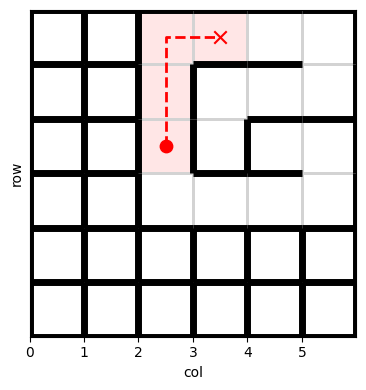



SAMPLE 2  (dataset index 7613)
Input tokens (trimmed PAD):
['<ADJLIST_START>', '(1,4)', '<-->', '(0,4)', ';', '(2,5)', '<-->', '(3,5)', ';', '(0,5)', '<-->', '(1,5)', ';', '(2,4)', '<-->', '(1,4)', ';', '(4,5)', '<-->', '(4,4)', ';', '(0,5)', '<-->', '(0,4)', ';', '(2,5)', '<-->', '(2,4)', ';', '(3,5)', '<-->', '(4,5)', ';', '<ADJLIST_END>', '<ORIGIN_START>', '(3,5)', '<ORIGIN_END>', '<TARGET_START>', '(0,5)', '<TARGET_END>', '<PATH_START>']

Ground Truth tokens:
['<SOS>', '(3,5)', '(2,5)', '(2,4)', '(1,4)', '(0,4)', '(0,5)', '<PATH_END>']

Predicted tokens:
['(0,5)', '(0,4)', '(1,4)', '(2,4)', '(2,5)', '(3,5)', '<PATH_END>']

Visualization:
Saved maze plot to: /kaggle/working/maze_plot_3bdc174d.png


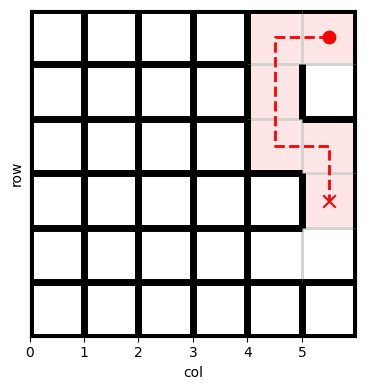



SAMPLE 3  (dataset index 13977)
Input tokens (trimmed PAD):
['<ADJLIST_START>', '(2,0)', '<-->', '(3,0)', ';', '(1,0)', '<-->', '(2,0)', ';', '(1,2)', '<-->', '(1,1)', ';', '(0,4)', '<-->', '(1,4)', ';', '(3,1)', '<-->', '(4,1)', ';', '(5,1)', '<-->', '(5,0)', ';', '(4,0)', '<-->', '(5,0)', ';', '(3,2)', '<-->', '(2,2)', ';', '(3,3)', '<-->', '(2,3)', ';', '(2,4)', '<-->', '(1,4)', ';', '(0,4)', '<-->', '(0,3)', ';', '(2,2)', '<-->', '(2,1)', ';', '(2,3)', '<-->', '(2,4)', ';', '(3,0)', '<-->', '(4,0)', ';', '(1,2)', '<-->', '(0,2)', ';', '(1,0)', '<-->', '(0,0)', ';', '(0,1)', '<-->', '(0,2)', ';', '(2,1)', '<-->', '(3,1)', ';', '(0,0)', '<-->', '(0,1)', ';', '(3,2)', '<-->', '(3,3)', ';', '(5,1)', '<-->', '(4,1)', ';', '<ADJLIST_END>', '<ORIGIN_START>', '(2,1)', '<ORIGIN_END>', '<TARGET_START>', '(2,4)', '<TARGET_END>', '<PATH_START>']

Ground Truth tokens:
['<SOS>', '(2,1)', '(2,2)', '(3,2)', '(3,3)', '(2,3)', '(2,4)', '<PATH_END>']

Predicted tokens:
['(2,1)', '(2,0)', '(1,0)', '

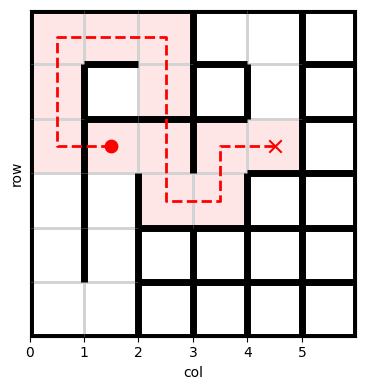



SAMPLE 4  (dataset index 5875)
Input tokens (trimmed PAD):
['<ADJLIST_START>', '(5,3)', '<-->', '(4,3)', ';', '(5,4)', '<-->', '(4,4)', ';', '(5,4)', '<-->', '(5,3)', ';', '(1,5)', '<-->', '(1,4)', ';', '(3,4)', '<-->', '(2,4)', ';', '(4,2)', '<-->', '(4,3)', ';', '(3,2)', '<-->', '(2,2)', ';', '(1,5)', '<-->', '(2,5)', ';', '(3,4)', '<-->', '(4,4)', ';', '(3,3)', '<-->', '(2,3)', ';', '(4,2)', '<-->', '(3,2)', ';', '(2,5)', '<-->', '(2,4)', ';', '(2,3)', '<-->', '(2,2)', ';', '<ADJLIST_END>', '<ORIGIN_START>', '(3,4)', '<ORIGIN_END>', '<TARGET_START>', '(3,2)', '<TARGET_END>', '<PATH_START>']

Ground Truth tokens:
['<SOS>', '(3,4)', '(4,4)', '(5,4)', '(5,3)', '(4,3)', '(4,2)', '(3,2)', '<PATH_END>']

Predicted tokens:
['(3,4)', '(4,4)', '(5,4)', '(5,3)', '(4,3)', '(4,2)', '(3,2)', '<PATH_END>']

Visualization:
Saved maze plot to: /kaggle/working/maze_plot_7fc8dd9a.png


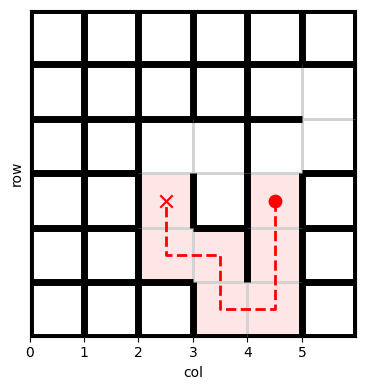



SAMPLE 5  (dataset index 5754)
Input tokens (trimmed PAD):
['<ADJLIST_START>', '(3,2)', '<-->', '(2,2)', ';', '(4,2)', '<-->', '(4,1)', ';', '(3,1)', '<-->', '(4,1)', ';', '(5,1)', '<-->', '(5,0)', ';', '(5,5)', '<-->', '(4,5)', ';', '(4,0)', '<-->', '(3,0)', ';', '(3,4)', '<-->', '(4,4)', ';', '(2,0)', '<-->', '(3,0)', ';', '(2,0)', '<-->', '(1,0)', ';', '(4,5)', '<-->', '(4,4)', ';', '(0,3)', '<-->', '(1,3)', ';', '(5,5)', '<-->', '(5,4)', ';', '(5,0)', '<-->', '(4,0)', ';', '(4,3)', '<-->', '(3,3)', ';', '(3,2)', '<-->', '(4,2)', ';', '(5,2)', '<-->', '(5,1)', ';', '(0,0)', '<-->', '(0,1)', ';', '(2,1)', '<-->', '(1,1)', ';', '(3,1)', '<-->', '(2,1)', ';', '(1,1)', '<-->', '(0,1)', ';', '(4,3)', '<-->', '(5,3)', ';', '(3,3)', '<-->', '(3,4)', ';', '(1,2)', '<-->', '(1,3)', ';', '(0,0)', '<-->', '(1,0)', ';', '(5,2)', '<-->', '(5,3)', ';', '(1,2)', '<-->', '(2,2)', ';', '<ADJLIST_END>', '<ORIGIN_START>', '(3,0)', '<ORIGIN_END>', '<TARGET_START>', '(5,1)', '<TARGET_END>', '<PATH_STA

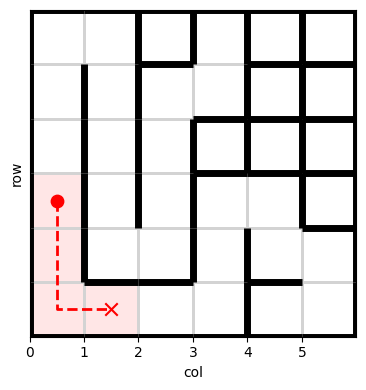

In [136]:
transformer_random_inference_samples(
    model=model,
    test_src=test_src,
    test_tgt=test_tgt,
    id_to_token=id2tok,
    num_samples=5
)
